In [1]:
]activate ../../../../../

  Activating project at `~/UCLOneDrive/SpatialStructureInMicrobialCommunities/SSMCCode`

In [2]:
using Revise
includet("./run_corresponding_mms.jl")

In [3]:
using CairoMakie
CairoMakie.activate!()
using Statistics, ColorSchemes

# Paired SI / MM df
One row per (system, p): the SI run and its MM run with d fitted at that p. `biomass` is total strain biomass, `num_saved x sN`; `tot_biomass` is its integral over space.

In [4]:
function load_paired_df(; si_dir="../data", mm_dir="main1")
    si = load("../systems.jld2")
    si_pde_df, mm_pde_df = si["pde_df"], load("setup.jld2", "pde_df")

    function read_run(fname, Ns, L)
        jldopen(fname) do d
            us = d["saved_us"]
            biomass = Matrix{Float64}(undef, length(us), size(us[1], 2))
            for k in eachindex(us)
                @views sum!(biomass[k:k, :], us[k][1:Ns, :])
            end
            (;
                pde_df_row=d["pde_df_row"], retcode=d["retcode"], final_T=d["final_T"],
                maxresid=d["maxresid"], num_saved=d["num_saved"], realtime=d["realtime"],
                final_state=d["final_state"], ts=d["saved_ts"], biomass,
                tot_biomass=vec(sum(biomass; dims=2)) .* (L / size(biomass, 2)),
            )
        end
    end
    prefixed(pre, nt) = (Symbol(pre, k) => v for (k, v) in pairs(nt))

    rows = @showprogress map(1:nrow(si_pde_df)) do i
        r = si_pde_df[i, :]
        j = only(findall((mm_pde_df.sys_i .== r.sys_i) .& (mm_pde_df.p .== r.p) .& (mm_pde_df.fit_p .== r.p)))
        Ns = get_Ns(r.params)[1]
        si_run = read_run(joinpath(si_dir, @sprintf("row%04d.jld2", i)), Ns, r.L)
        mm_run = read_run(joinpath(mm_dir, @sprintf("row%04d.jld2", j)), 1, r.L)
        GC.gc()
        (; r.sys_i, r.df_row, r.p, r.L, r.sN, r.T, Ns, fit_d=mm_pde_df.fit_d[j],
            prefixed("si_", si_run)..., prefixed("mm_", mm_run)...)
    end

    md = (;
        si=si["metadata"],
        si_solver=load(joinpath(si_dir, "settings.jld2"), "settings")[(:abstol, :reltol, :maxtime)],
        mm_solver=load(joinpath(mm_dir, "settings.jld2"), "settings")[(:abstol, :reltol, :maxtime, :save_step)],
    )
    DataFrame(rows), md
end

adf, md = load_paired_df()
nrow(adf), Base.summarysize(adf) / 1e6

Progress: 100%|█████████████████████████████████████████| Time: 0:00:11

(40, 242.94052)

# Playing around

In [8]:
names(adf)

28-element Vector{String}:
 "sys_i"
 "df_row"
 "p"
 "L"
 "sN"
 "T"
 "Ns"
 "fit_d"
 "si_pde_df_row"
 "si_retcode"
 "si_final_T"
 "si_maxresid"
 "si_num_saved"
 ⋮
 "si_biomass"
 "si_tot_biomass"
 "mm_pde_df_row"
 "mm_retcode"
 "mm_final_T"
 "mm_maxresid"
 "mm_num_saved"
 "mm_realtime"
 "mm_final_state"
 "mm_ts"
 "mm_biomass"
 "mm_tot_biomass"

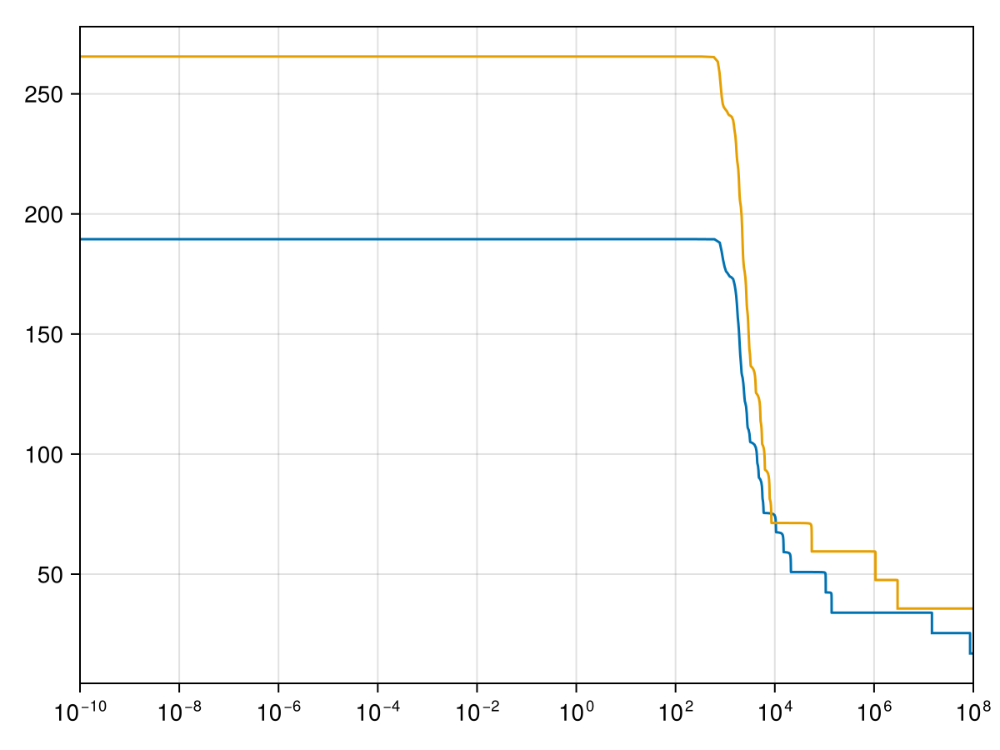

In [75]:
r = adf[38,:];
fig = Figure()
ax = Axis(fig[1,1];
    xscale=log10,
)

lines!(ax, r.si_ts, r.si_tot_biomass)
lines!(ax, r.mm_ts, r.mm_tot_biomass)

xlims!(1e-10, r.T)

fig

# Total biomass in time, all rows

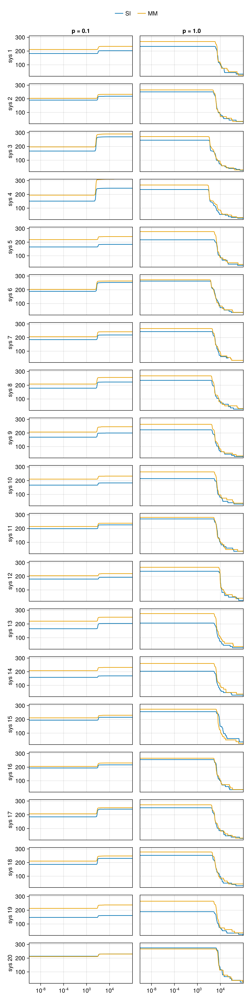

In [10]:
sys_is = sort(unique(adf.sys_i))
ps = sort(unique(adf.p))
ylo, yhi = extrema(vcat(adf.si_tot_biomass..., adf.mm_tot_biomass...))

fig = Figure(; size=(300 * length(ps), 120 * length(sys_is)))
axs = Axis[]
for (i, s) in enumerate(sys_is), (j, p) in enumerate(ps)
    r = only(eachrow(adf[(adf.sys_i.==s).&(adf.p.==p), :]))
    ax = Axis(fig[i, j]; xscale=log10,
        xticks=(10.0 .^ (-8:4:4), [rich("10", superscript(string(e))) for e in -8:4:4]))
    lines!(ax, r.si_ts, r.si_tot_biomass; label="SI")
    lines!(ax, r.mm_ts, r.mm_tot_biomass; label="MM")
    xlims!(ax, 1e-10, r.T)
    ylims!(ax, ylo, yhi)
    i == 1 && (ax.title = "p = $p")
    j == 1 && (ax.ylabel = "sys $s")
    i < length(sys_is) && hidexdecorations!(ax; grid=false)
    j > 1 && hideydecorations!(ax; grid=false)
    push!(axs, ax)
end
Legend(fig[0, :], axs[1]; orientation=:horizontal, framevisible=false)

Makie.save("./totbiom_vs_t.pdf", fig)

fig

# Final states, all rows
Strain densities over space, SI (each strain a line) above MM N.

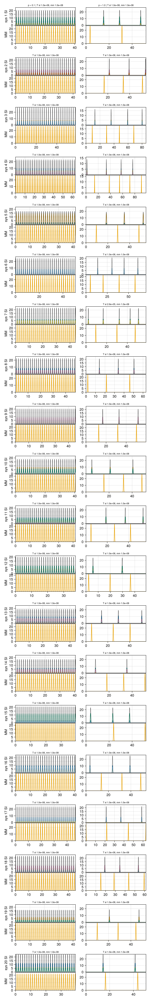

In [9]:
sys_is = sort(unique(adf.sys_i))
ps = sort(unique(adf.p))

fig = Figure(; size=(300 * length(ps), 200 * length(sys_is)))
for (i, s) in enumerate(sys_is), (j, p) in enumerate(ps)
    r = only(eachrow(adf[(adf.sys_i.==s).&(adf.p.==p), :]))
    xs = range(0, r.L; length=r.sN + 1)[1:end-1] .+ r.L / 2r.sN
    si_tot = vec(sum(r.si_final_state[1:r.Ns, :]; dims=1))
    yhi = max(maximum(si_tot), maximum(r.mm_final_state[1, :]))
    gl = fig[i, j] = GridLayout()
    ax_si = Axis(gl[1, 1])
    ax_mm = Axis(gl[2, 1])
    for a in 1:r.Ns
        lines!(ax_si, xs, r.si_final_state[a, :])
    end
    lines!(ax_si, xs, si_tot; color=:black, linewidth=0.7)
    lines!(ax_mm, xs, r.mm_final_state[1, :]; color=Makie.wong_colors()[2])
    for ax in (ax_si, ax_mm)
        xlims!(ax, 0, r.L)
        ylims!(ax, 0, yhi)
    end
    hidexdecorations!(ax_si; grid=false)
    rowgap!(gl, 2)
    ax_si.title = @sprintf("%sT si %.1e, mm %.1e", i == 1 ? "p = $p | " : "", r.si_final_T, r.mm_final_T)
    ax_si.titlesize = 9
    ax_si.titlefont = :regular
    j == 1 && (ax_si.ylabel = "sys $s SI"; ax_mm.ylabel = "MM")
end

Makie.save("./final_states.pdf", fig)

fig

# Space-time, all rows
SI (`plot_spacetime_composition!`, colour = composition, alpha = total biomass) next to MM total biomass.

In [6]:
4+4

8

Progress: 100%|█████████████████████████████████████████| Time: 0:00:23




In [8]:
sys_is = sort(unique(adf.sys_i))
ps = sort(unique(adf.p))
st_tmin = 1e0 # nothing moves before t ~ 1

fig = Figure(; size=(2 * 220 * length(ps), 280 * length(sys_is)))
@showprogress for (i, s) in enumerate(sys_is), (j, p) in enumerate(ps)
    r = only(eachrow(adf[(adf.sys_i.==s).&(adf.p.==p), :]))
    dx = r.L / r.sN
    gl = fig[i, j] = GridLayout()

    si_ts, si_us = jldopen(d -> (d["saved_ts"], d["saved_us"]), joinpath("../data", @sprintf("row%04d.jld2", r.si_pde_df_row)))
    si = plot_spacetime_composition!(gl[1, 1], si_ts, si_us, r.Ns, dx; tmin=st_tmin, quiet=true)
    si_us = nothing

    mm_us = [reshape(r.mm_biomass[k, :], 1, :) for k in axes(r.mm_biomass, 1)]
    mm = plot_spacetime_biomass!(gl[1, 2], r.mm_ts, mm_us, 1, dx; tmin=st_tmin, quiet=true, colormap=:Greys)

    for ax in (si.ax, mm.ax)
        ylims!(ax, st_tmin, r.T)
        xlims!(ax, 0, r.L)
        i < length(sys_is) && (ax.xlabel = "")
    end
    si.ax.title = @sprintf("%ssys %d SI, T %.1e", i == 1 ? "p = $p | " : "", s, r.si_final_T)
    mm.ax.title = @sprintf("MM, T %.1e", r.mm_final_T)
    for ax in (si.ax, mm.ax)
        ax.titlesize = 9
        ax.titlefont = :regular
    end
    hideydecorations!(mm.ax; ticks=false)
    j > 1 && (si.ax.ylabel = "")
    colgap!(gl, 4)

    si.hm.rasterize = 2
    mm.hm.rasterize = 2
    
    GC.gc()
end

Makie.save("./spacetime_diagrams.pdf", fig)

fig

# SI ecosystem diagrams
`diagram_sfss_v3` at the well-mixed steady state, one per system.




In [100]:
diag_strain_threshold = 0.1
diag_edge_threshold = 1e-3

sys_is = sort(unique(adf.sys_i))
diag_imgs = let si_pde_df = load("../systems.jld2", "pde_df")
    map(sys_is) do s
        r = si_pde_df[findfirst(==(s), si_pde_df.sys_i), :]
        diagram_image(diagram_sfss_v3(r.params, r.ode_hss;
            strain_threshold=diag_strain_threshold,
            edge_threshold=diag_edge_threshold
        ))
    end
end

fig = Figure(; size=(1000, 450 * length(sys_is)))
for (i, (s, img)) in enumerate(zip(sys_is, diag_imgs))
    ax = Axis(fig[i, 1]; aspect=DataAspect(), title="sys $s", titlesize=11, titlefont=:regular)
    image!(ax, img)
    hidedecorations!(ax)
    hidespines!(ax)
end

fig

# System overview
Per system: strain count and well-mixed total biomass, diagram, SI and fitted MM disprels at each p.

In [101]:
ov_strain_threshold = 0.1
ov_edge_threshold = 0.0

sys_is = sort(unique(adf.sys_i))
ps = sort(unique(adf.p))
si_pde_df = load("../systems.jld2", "pde_df")
fits = load("fits.jld2")
fit_ks = fits["fit_ks"]

fig = Figure(; size=(1700, 380 * length(sys_is)))
for (i, s) in enumerate(sys_is)
    r = si_pde_df[findfirst(==(s), si_pde_df.sys_i), :]
    Ns = get_Ns(r.params)[1]

    Label(fig[i, 1], @sprintf("sys %d\n%d strains, biomass %.3g", s, Ns, sum(r.ode_hss[1:Ns]));
        rotation=pi / 2, tellheight=false)

    ax = Axis(fig[i, 2]; aspect=DataAspect())
    image!(ax, diagram_image(diagram_sfss_v3(r.params, r.ode_hss;
        strain_threshold=ov_strain_threshold, edge_threshold=ov_edge_threshold)))
    hidedecorations!(ax)
    hidespines!(ax)

    for (j, p) in enumerate(ps)
        f = only(eachrow(fits["fits_df"][(fits["fits_df"].sys_i.==s).&(fits["fits_df"].fit_p.==p), :]))
        ax = Axis(fig[i, 2+j]; xscale=log10, title=@sprintf("p = %g, d = %.3g", p, f.fit_d),
            titlesize=11, titlefont=:regular)
        hlines!(ax, 0; color=:black, linewidth=0.5)
        lines!(ax, fit_ks, f.si_mrls; label="SI")
        lines!(ax, fit_ks, f.mmls; label="MM", linestyle=:dash)
        xlims!(ax, f.si_k / 30, f.si_k * 30)
        ylims!(ax, -2f.si_h, 1.5f.si_h)
        i == length(sys_is) && (ax.xlabel = "k")
        j == 1 && (ax.ylabel = "max Re λ")
        i == 1 && j == length(ps) && axislegend(ax; position=:rb, framevisible=false)
    end
end
colsize!(fig.layout, 1, 40)
colsize!(fig.layout, 2, Relative(0.5))

Makie.save("./system_overview.pdf", fig)

fig